# Keras CNN on MNIST

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_23 (Conv2D)                   │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_24 (Conv2D)                   │ (None, 24, 24, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_12 (MaxPooling2D)      │ (None, 12, 12, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_23 (Dropout)                 │ (None, 12, 12, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_12 (Flatten)                 │ (None, 9216)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_23 (Dense)                     │ (None, 128)                 │       1,179,776 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_24 (Dropout)                 │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_24 (Dense)                     │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

Total params: 1,199,882 (4.58 MB)

Trainable params: 1,199,882 (4.58 MB)

Non-trainable params: 0 (0.00 B)

Epoch 1/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 81ms/step - accuracy: 0.3578 - loss: 1.8539 - val_accuracy: 0.8200 - val_loss: 0.6012
Epoch 2/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 51ms/step - accuracy: 0.7881 - loss: 0.6947 - val_accuracy: 0.8800 - val_loss: 0.3071
Epoch 3/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - accuracy: 0.8714 - loss: 0.4448 - val_accuracy: 0.9400 - val_loss: 0.2013
Epoch 4/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - accuracy: 0.9106 - loss: 0.2780 - val_accuracy: 0.9900 - val_loss: 0.1142
Epoch 5/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - accuracy: 0.9302 - loss: 0.2596 - val_accuracy: 0.9800 - val_loss: 0.0938
Epoch 6/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 51ms/step - accuracy: 0.9464 - loss: 0.1689 - val_accuracy: 0.9700 - val_loss: 0.0990
Epoch 7/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - accuracy: 0.9526 - loss: 0.1612 - val_accuracy: 0.9700 - val_loss: 0.0778
Epoch 8/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - accuracy: 0.9448 - loss: 0.1726 - val_accuracy: 0.9700 - v

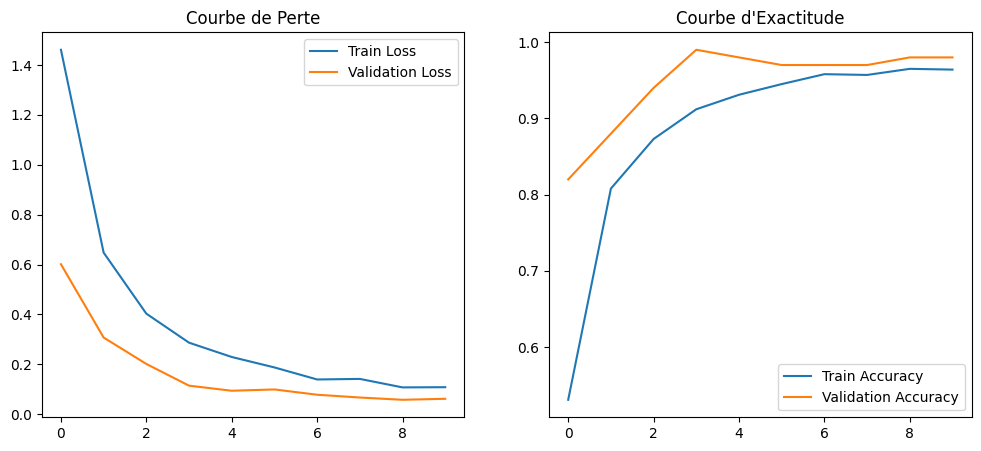

In [42]:
import tensorflow as tf
from keras.datasets import mnist
from keras.utils import to_categorical
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Dropout, Flatten, Dense
import numpy as np
import matplotlib.pyplot as plt

# 1. Chargement des données et extraction de 1000 exemples pour l'apprentissage et 100 exemples pour le test
(x_train, y_train), (x_test, y_test) = mnist.load_data()

x_train, y_train = x_train[:1000], y_train[:1000]
x_test, y_test = x_test[:100], y_test[:100]

# 2. Transformation en tenseurs de dimension (nombre_images, largeur, longueur, 1)
x_train = x_train.reshape((x_train.shape[0], 28, 28, 1))
x_test = x_test.reshape((x_test.shape[0], 28, 28, 1))

# 3. Normalisation des niveaux de gris entre 0 et 1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# 4. Transformation des labels en données qualitatives (one-hot encoding)
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# 5. Création du réseau de neurones convolutionnel
model = Sequential([
    Conv2D(32, kernel_size=(3,3), activation="relu", input_shape=(28, 28, 1)),
    Conv2D(64, kernel_size=(3,3), activation="relu"),
    MaxPooling2D(pool_size=(2,2)),
    Dropout(0.25),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(10, activation="softmax")  # 10 classes pour les chiffres 0 à 9
])

# 6. Affichage de la description du réseau
model.summary()

# 7. Compilation, apprentissage et évaluation
model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

# Entraînement du modèle
history = model.fit(x_train, y_train, epochs=10, batch_size=32, validation_data=(data_test, labels_test))

# Évaluation du modèle
test_loss, test_acc = model.evaluate(data_test, labels_test, verbose=2)
print(f"\nPrécision sur le jeu de test : {test_acc:.4f}")

# Affichage des courbes de perte et d'exactitude
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.title("Courbe de Perte")

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.legend()
plt.title("Courbe d'Exactitude")

plt.show()


In [43]:
import tensorflow as tf
from keras.datasets import mnist
from keras.utils import to_categorical
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Dropout, Flatten, Dense
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# ===============================================================
# 1. CHARGEMENT DE LA BASE MNIST ET EXTRACTION DE 1000 EXEMPLES POUR L'APPRENTISSAGE ET 100 POUR LE TEST
# ===============================================================

(data_train, labels_train), (data_test, labels_test) = mnist.load_data()

# Sélectionner uniquement 1000 images pour l'entraînement et 100 pour le test
data_train, labels_train = data_train[:1000], labels_train[:1000]
data_test, labels_test = data_test[:100], labels_test[:100]

print("✅ Étape 1 : Chargement des données terminé.")
print(f"data_train.shape : {data_train.shape}")
print(f"data_test.shape : {data_test.shape}")

✅ Étape 1 : Chargement des données terminé.
data_train.shape : (1000, 28, 28)
data_test.shape : (100, 28, 28)


In [44]:
# ===============================================================
# 2. TRANSFORMATION DES ENSEMBLES D'APPRENTISSAGE ET DE TEST EN TENSEURS DE DIMENSION (nombre_images, largeur, longueur, 1)
# ===============================================================

data_train = data_train.reshape((data_train.shape[0], 28, 28, 1))
data_test = data_test.reshape((data_test.shape[0], 28, 28, 1))

print("✅ Étape 2 : Transformation en tenseurs 4D effectuée.")
print(f"Nouvelle shape de data_train : {data_train.shape}")
print(f"Nouvelle shape de data_test : {data_test.shape}")

✅ Étape 2 : Transformation en tenseurs 4D effectuée.
Nouvelle shape de data_train : (1000, 28, 28, 1)
Nouvelle shape de data_test : (100, 28, 28, 1)


In [45]:
# ===============================================================
# 3. NORMALISATION DES NIVEAUX DE GRIS POUR LES RAMENER ENTRE 0 ET 1
# ===============================================================

data_train = data_train.astype("float32") / 255.0
data_test = data_test.astype("float32") / 255.0

print("✅ Étape 3 : Normalisation des images effectuée.")
print(f"Valeurs min/max après normalisation : {np.min(data_train)}/{np.max(data_train)}")

✅ Étape 3 : Normalisation des images effectuée.
Valeurs min/max après normalisation : 0.0/1.0


In [46]:
# ===============================================================
# 4. TRANSFORMATION DES DONNÉES y_test ET y_train EN DONNÉES QUALITATIVES (ONE-HOT)
# ===============================================================

labels_train = to_categorical(labels_train, 10)
labels_test = to_categorical(labels_test, 10)

print("✅ Étape 4 : Transformation des labels en one-hot encoding effectuée.")
print(f"Nouvelle shape de labels_train : {labels_train.shape}")
print(f"Nouvelle shape de labels_test : {labels_test.shape}")

✅ Étape 4 : Transformation des labels en one-hot encoding effectuée.
Nouvelle shape de labels_train : (1000, 10)
Nouvelle shape de labels_test : (100, 10)


In [47]:
# ===============================================================
# 5. CRÉATION DU MODÈLE CNN AVEC L'ARCHITECTURE DEMANDÉE
# ===============================================================

model = Sequential([
    Conv2D(32, kernel_size=(3,3), activation="relu", input_shape=(28, 28, 1)),  # Couche convolutionnelle 1
    MaxPooling2D(pool_size=(2,2)),  # Couche de Pooling
    Dropout(0.25),  # Couche Dropout
    Flatten(),  # Transformation en un vecteur plat
    Dense(128, activation="relu"),  # Couche Dense
    Dropout(0.5),  # Deuxième Dropout
    Dense(10, activation="softmax")  # Couche de sortie avec 10 neurones
])

# ===============================================================
# 6. AFFICHAGE DE LA DESCRIPTION DU MODÈLE
# ===============================================================

model.summary()

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_25 (Conv2D)                   │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_13 (MaxPooling2D)      │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_25 (Dropout)                 │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_13 (Flatten)                 │ (None, 5408)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_25 (Dense)                     │ (None, 128)                 │         692,352 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_26 (Dropout)                 │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_26 (Dense)                     │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

Total params: 693,962 (2.65 MB)

Trainable params: 693,962 (2.65 MB)

Non-trainable params: 0 (0.00 B)

In [48]:
# ===============================================================
# 7. COMPILATION, APPRENTISSAGE ET ÉVALUATION DU MODÈLE
# ===============================================================

# Compilation du modèle
model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
print("\n\n\n Étape 7.1 : Compilation du modèle effectuée.")

# Entraînement du modèle
history = model.fit(data_train, labels_train, epochs=50, batch_size=128, verbose=2, validation_data=(data_test, labels_test))
print("\n\n\n Étape 7.2 : Entraînement du modèle terminé.")

# Évaluation du modèle
test_loss, test_acc = model.evaluate(data_test, labels_test, verbose=2)
print(f"\n\n\n Étape 7.3 : Précision sur le jeu de test : {test_acc:.4f}")





 Étape 7.1 : Compilation du modèle effectuée.
Epoch 1/50
8/8 - 2s - 219ms/step - accuracy: 0.3700 - loss: 1.9456 - val_accuracy: 0.7200 - val_loss: 1.3148
Epoch 2/50
8/8 - 0s - 57ms/step - accuracy: 0.7000 - loss: 1.1046 - val_accuracy: 0.7900 - val_loss: 0.7119
Epoch 3/50
8/8 - 1s - 83ms/step - accuracy: 0.7660 - loss: 0.7469 - val_accuracy: 0.8100 - val_loss: 0.5701
Epoch 4/50
8/8 - 1s - 73ms/step - accuracy: 0.8240 - loss: 0.5683 - val_accuracy: 0.8500 - val_loss: 0.4365
Epoch 5/50
8/8 - 1s - 77ms/step - accuracy: 0.8460 - loss: 0.4771 - val_accuracy: 0.8600 - val_loss: 0.3811
Epoch 6/50
8/8 - 1s - 78ms/step - accuracy: 0.8770 - loss: 0.4282 - val_accuracy: 0.8400 - val_loss: 0.3679
Epoch 7/50
8/8 - 1s - 78ms/step - accuracy: 0.8850 - loss: 0.3773 - val_accuracy: 0.8900 - val_loss: 0.2838
Epoch 8/50
8/8 - 1s - 75ms/step - accuracy: 0.8980 - loss: 0.3362 - val_accuracy: 0.8700 - val_loss: 0.2895
Epoch 9/50
8/8 - 0s - 41ms/step - accuracy: 0.9160 - loss: 0.3221 - val_accuracy: 0.91

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


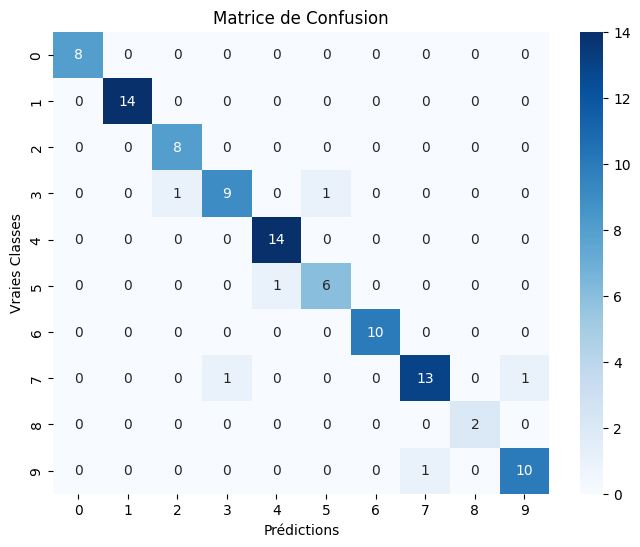




 ✅ Étape finale : Affichage de la matrice de confusion terminé.


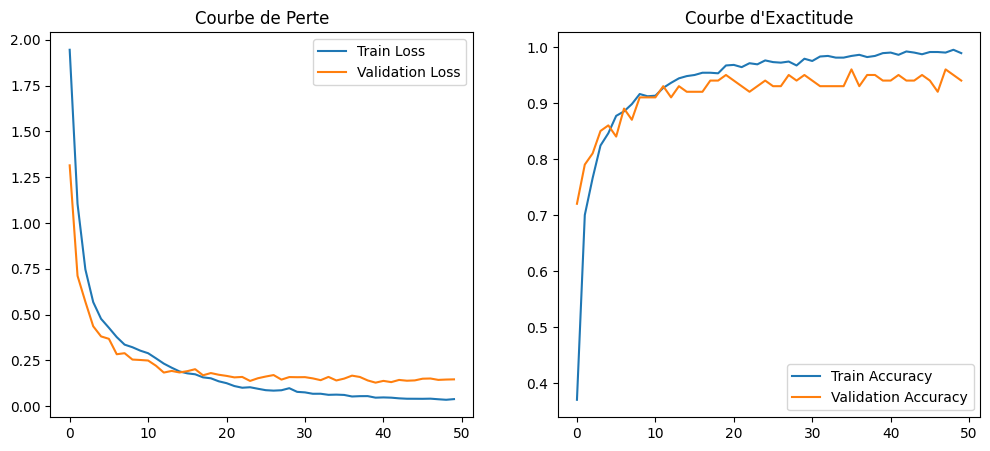

✅ Étape finale : Affichage des courbes de performance terminé.



 ✅ Rapport de Classification :
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         8
           1       1.00      1.00      1.00        14
           2       0.89      1.00      0.94         8
           3       0.90      0.82      0.86        11
           4       0.93      1.00      0.97        14
           5       0.86      0.86      0.86         7
           6       1.00      1.00      1.00        10
           7       0.93      0.87      0.90        15
           8       1.00      1.00      1.00         2
           9       0.91      0.91      0.91        11

    accuracy                           0.94       100
   macro avg       0.94      0.95      0.94       100
weighted avg       0.94      0.94      0.94       100



In [49]:
# ===============================================================
# 🔷 MATRICE DE CONFUSION
# ===============================================================

# Prédictions du modèle
y_pred = model.predict(data_test)
y_pred_classes = np.argmax(y_pred, axis=1)  # Convertit les probabilités softmax en classes
y_true_classes = np.argmax(labels_test, axis=1)  # Convertit les labels one-hot en classes

# Calcul de la matrice de confusion
conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)

# Affichage avec Seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=range(10), yticklabels=range(10))
plt.xlabel("Prédictions")
plt.ylabel("Vraies Classes")
plt.title("Matrice de Confusion")
plt.show()

print("\n\n\n ✅ Étape finale : Affichage de la matrice de confusion terminé.")

# ===============================================================
# 🔷 AFFICHAGE DES COURBES DE PERFORMANCE (PERTE & PRÉCISION)
# ===============================================================

plt.figure(figsize=(12, 5))

# Courbe de la perte
plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.title("Courbe de Perte")

# Courbe de l'exactitude
plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.legend()
plt.title("Courbe d'Exactitude")

plt.show()

print("✅ Étape finale : Affichage des courbes de performance terminé.")

# ===============================================================
# 🔷 RAPPORT DE CLASSIFICATION
# ===============================================================

print("\n\n\n ✅ Rapport de Classification :")
print(classification_report(y_true_classes, y_pred_classes))

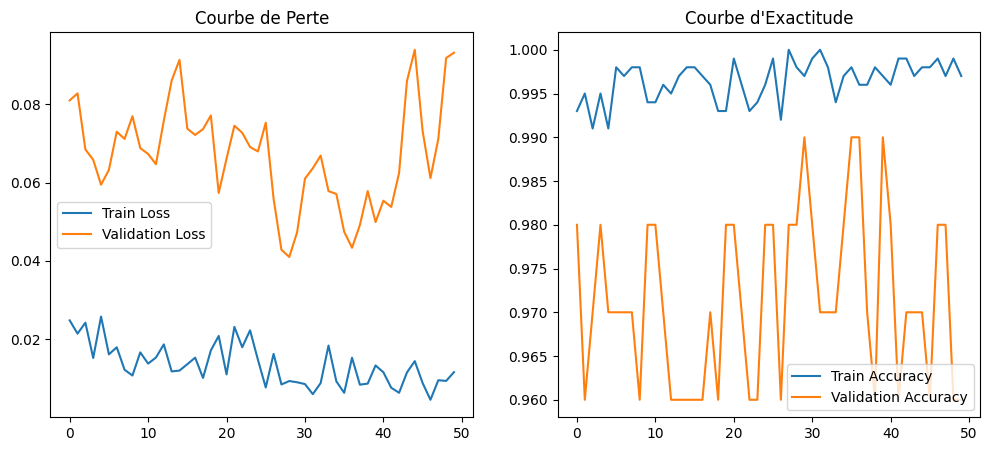

✅ Étape finale : Affichage des courbes de performance terminé.


In [39]:






































































# ===============================================================
# AFFICHAGE DES COURBES DE PERFORMANCE (PERTE & PRÉCISION)
# ===============================================================

plt.figure(figsize=(12, 5))

# Courbe de la perte
plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.title("Courbe de Perte")

# Courbe de l'exactitude
plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.legend()
plt.title("Courbe d'Exactitude")

plt.show()

print("✅ Étape finale : Affichage des courbes de performance terminé.")